⏳ Đang tải dữ liệu ETHUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Đang chạy Backtest LinReg + KC + RSI Strategy...

METRICS (LinReg + KC + RSI Triple Confirmation)
     Final Equity: 18603.5815
     Total Return: 0.8604
    CAGR (approx): 0.3368
     Max Drawdown: -0.1345
           Sharpe: 1.7547
           Trades: 274
          Winrate: 0.4161
    Avg PnL/Trade: 31.3999
    Profit Factor: 1.3752
           Max DD: -0.134468518382


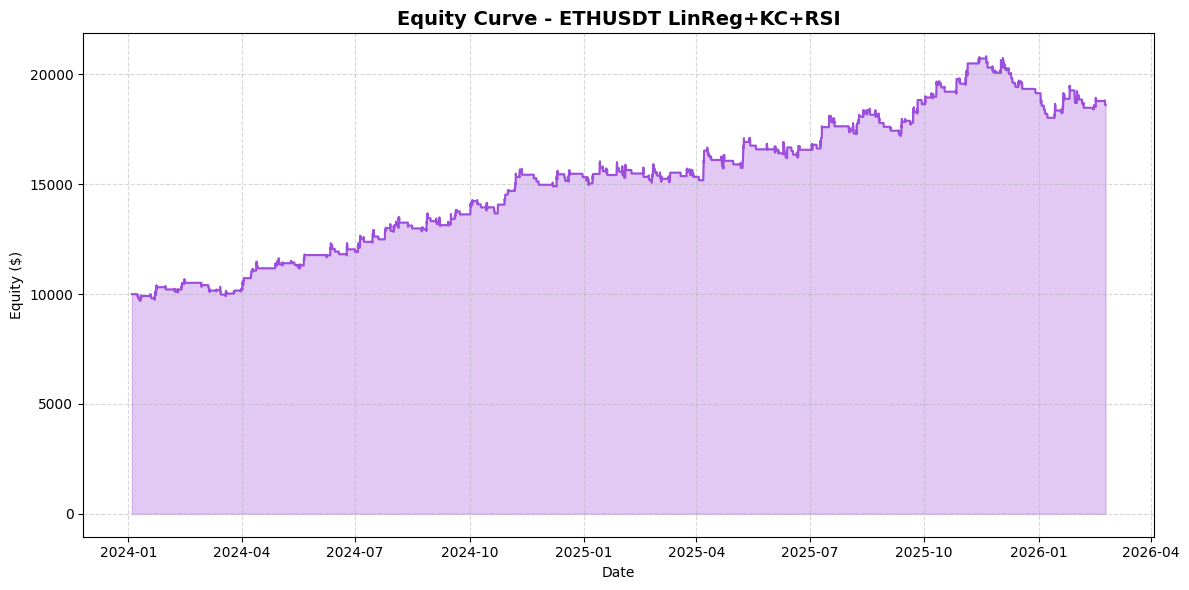


📊 Sample Trades (first 10):
            Exit Time   Type        Entry         Exit         PnL       Reason       Balance
0 2024-01-08 06:00:00  SHORT  2178.953135  2201.847196 -100.000000    Stop Loss   9900.000000
1 2024-01-09 00:00:00   LONG  2335.980000  2305.809961  -99.000000    Stop Loss   9801.000000
2 2024-01-10 02:00:00   LONG  2398.640000  2355.395335  -98.010000    Stop Loss   9702.990000
3 2024-01-11 13:00:00   LONG  2516.237437  2635.980000  212.811973    Time Exit   9915.801973
4 2024-01-19 10:00:00  SHORT  2463.600000  2489.934580  -99.158020    Stop Loss   9816.643953
5 2024-01-22 10:00:00  SHORT  2426.938557  2379.025101  296.233840  Take Profit  10112.877793
6 2024-01-22 13:00:00  SHORT  2378.078485  2400.555848 -101.128778    Stop Loss  10011.749015
7 2024-01-23 09:00:00  SHORT  2334.217177  2260.752227  278.050657  Take Profit  10289.799672
8 2024-01-24 03:00:00  SHORT  2223.350000  2213.450000   29.208209    Time Exit  10319.007882
9 2024-01-30 23:00:00   LONG  2

In [2]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --- 1. HÀM TẢI DỮ LIỆU ---
def str_to_millis(date_str):
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol, interval, start_str, end_str):
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")
    
    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(general_url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break
            data = response.json()
            if not data: break
            all_klines.extend(data)
            last_ts = data[-1][0]
            start_time = last_ts + 1
            time.sleep(0.05) 
        except Exception as e:
            print(f"Lỗi: {e}")
            break

    if not all_klines: return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df

# --- 2. HÀM TÍNH CHỈ BÁO ---
def calculate_indicators(df):
    data = df.copy()
    
    # True Range
    data['prev_close'] = data['Close'].shift(1)
    data['h_l'] = data['High'] - data['Low']
    data['h_pc'] = (data['High'] - data['prev_close']).abs()
    data['l_pc'] = (data['Low'] - data['prev_close']).abs()
    data['TR'] = data[['h_l', 'h_pc', 'l_pc']].max(axis=1)
    
    # ATR function
    def calc_atr(series_tr, period):
        return series_tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    
    # ATR các period
    data['ATR_20'] = calc_atr(data['TR'], 20)
    data['ATR_25'] = calc_atr(data['TR'], 25)
    data['ATR_50'] = calc_atr(data['TR'], 50)
    
    # Linear Regression (77 period on Close)
    def calc_linreg(series, period):
        linreg = pd.Series(index=series.index, dtype=float)
        for i in range(period - 1, len(series)):
            y = series.iloc[i - period + 1:i + 1].values
            x = np.arange(period)
            # Linear regression: y = a*x + b
            coeffs = np.polyfit(x, y, 1)
            # Prediction at last point (x = period - 1)
            linreg.iloc[i] = coeffs[0] * (period - 1) + coeffs[1]
        return linreg
    
    data['LinReg_77'] = calc_linreg(data['Close'], 77)
    
    # RSI(40) on Close
    def calc_rsi(series, period):
        delta = series.diff()
        gain = (delta.where(delta > 0, 0)).rolling(window=period).mean()
        loss = (-delta.where(delta < 0, 0)).rolling(window=period).mean()
        rs = gain / loss
        rsi = 100 - (100 / (1 + rs))
        return rsi
    
    data['RSI_40'] = calc_rsi(data['Close'], 40)
    
    # Keltner Channel (35, dev=2.3)
    data['EMA_35'] = data['Close'].ewm(span=35, adjust=False).mean()
    data['ATR_35'] = calc_atr(data['TR'], 35)
    data['KC_Upper_35'] = data['EMA_35'] + (2.3 * data['ATR_35'])
    data['KC_Lower_35'] = data['EMA_35'] - (2.3 * data['ATR_35'])
    
    # Highest/Lowest Close trong 10 nến
    data['Highest_Close_10'] = data['Close'].rolling(window=10).max()
    data['Lowest_Close_10'] = data['Close'].rolling(window=10).min()
    
    data.dropna(inplace=True)
    return data

# --- 3. BACKTESTER ---
class LinRegKCRSIBacktester:
    def __init__(self, df, initial_balance=10000):
        self.df = df
        self.initial_balance = initial_balance
        self.balance = initial_balance
        self.equity_curve = [] 
        self.trades = []
        self.position = None 
        self.entry_price = 0
        self.sl = 0
        self.tp = 0
        self.entry_bar_idx = 0
        self.qty = 0
        self.pending_order = None 
        
        # Strategy Parameters
        self.risk_pct = 0.01  # 1%
        self.price_entry_mult = 2.4  # Entry buffer
        self.sl_coef = 1.5  # SL = 1.5 * ATR(20)
        self.tp_coef = 4.4  # TP = 4.4 * ATR(25)
        self.exit_after_bars = 16
        self.pending_expiration = 3
        
    def run(self):
        indices = self.df.index
        
        for i in range(len(self.df)):
            current_bar = self.df.iloc[i]
            idx = indices[i]
            
            # A. QUẢN LÝ LỆNH ĐANG MỞ
            if self.position is not None:
                # Check Exit After Bars
                bars_held = i - self.entry_bar_idx
                if bars_held >= self.exit_after_bars:
                    self.close_position(current_bar['Close'], idx, "Time Exit")
                    self.append_equity(idx)
                    continue
                
                # Check SL/TP
                if self.position == 'LONG':
                    if current_bar['Low'] <= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    
                    if current_bar['High'] >= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
                
                elif self.position == 'SHORT':
                    if current_bar['High'] >= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    
                    if current_bar['Low'] <= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
            
            # B. QUẢN LÝ PENDING ORDER
            if self.position is None and self.pending_order is not None:
                # Check expiration
                if i >= self.pending_order['expire_idx']:
                    self.pending_order = None
                else:
                    p_price = self.pending_order['price']
                    
                    if self.pending_order['type'] == 'BUY_STOP' and current_bar['High'] >= p_price:
                        self.open_position('LONG', max(p_price, current_bar['Open']), i, 
                                         self.pending_order['sl_dist'], 
                                         self.pending_order['tp_dist'])
                        self.pending_order = None
                    
                    elif self.pending_order['type'] == 'SELL_STOP' and current_bar['Low'] <= p_price:
                        self.open_position('SHORT', min(p_price, current_bar['Open']), i, 
                                         self.pending_order['sl_dist'], 
                                         self.pending_order['tp_dist'])
                        self.pending_order = None
            
            # C. TÍN HIỆU VÀO LỆNH
            if self.position is None and self.pending_order is None:
                # Cần ít nhất shift=4 để lấy RSI
                if i < 4:
                    self.append_equity(idx)
                    continue
                
                # Current Open
                open_current = current_bar['Open']
                
                # LinReg Filter (shift=1)
                linreg_shift1 = self.df.iloc[i-1]['LinReg_77']
                
                # RSI Momentum (shift=4 vs shift=3)
                rsi_shift4 = self.df.iloc[i-4]['RSI_40']
                rsi_shift3 = self.df.iloc[i-3]['RSI_40']
                
                # Keltner Filter (shift=1)
                kc_upper_shift1 = self.df.iloc[i-1]['KC_Upper_35']
                kc_lower_shift1 = self.df.iloc[i-1]['KC_Lower_35']
                
                # LONG SIGNAL (3 conditions)
                long_signal = (
                    open_current > linreg_shift1 and      # Above LinReg trend
                    rsi_shift4 < rsi_shift3 and           # RSI rising
                    open_current > kc_upper_shift1        # Above KC upper
                )
                
                # SHORT SIGNAL (3 conditions)
                short_signal = (
                    open_current < linreg_shift1 and      # Below LinReg trend
                    rsi_shift4 > rsi_shift3 and           # RSI falling
                    open_current < kc_lower_shift1        # Below KC lower
                )
                
                if not long_signal and not short_signal:
                    self.append_equity(idx)
                    continue
                
                # Entry parameters (shift=3)
                highest_close_shift3 = self.df.iloc[i-3]['Highest_Close_10']
                lowest_close_shift3 = self.df.iloc[i-3]['Lowest_Close_10']
                atr_50_shift3 = self.df.iloc[i-3]['ATR_50']
                
                # SL/TP parameters (shift=1)
                atr_20_shift1 = self.df.iloc[i-1]['ATR_20']
                atr_25_shift1 = self.df.iloc[i-1]['ATR_25']
                
                # CREATE PENDING ORDERS
                if long_signal:
                    entry_price = highest_close_shift3 + (self.price_entry_mult * atr_50_shift3)
                    sl_distance = self.sl_coef * atr_20_shift1
                    tp_distance = self.tp_coef * atr_25_shift1
                    
                    self.pending_order = {
                        'type': 'BUY_STOP',
                        'price': entry_price,
                        'sl_dist': sl_distance,
                        'tp_dist': tp_distance,
                        'expire_idx': i + self.pending_expiration
                    }
                
                elif short_signal and not long_signal:
                    entry_price = lowest_close_shift3 - (self.price_entry_mult * atr_50_shift3)
                    sl_distance = self.sl_coef * atr_20_shift1
                    tp_distance = self.tp_coef * atr_25_shift1
                    
                    self.pending_order = {
                        'type': 'SELL_STOP',
                        'price': entry_price,
                        'sl_dist': sl_distance,
                        'tp_dist': tp_distance,
                        'expire_idx': i + self.pending_expiration
                    }
            
            # D. APPEND EQUITY
            self.append_equity(idx)
    
    def append_equity(self, idx):
        """Tính equity bao gồm unrealized P&L"""
        mark_to_market = self.balance
        if self.position == 'LONG':
            current_price = self.df.loc[idx, 'Close']
            unrealized = (current_price - self.entry_price) * self.qty
            mark_to_market += unrealized
        elif self.position == 'SHORT':
            current_price = self.df.loc[idx, 'Close']
            unrealized = (self.entry_price - current_price) * self.qty
            mark_to_market += unrealized
        
        self.equity_curve.append({'time': idx, 'equity': mark_to_market})
    
    def open_position(self, pos_type, price, bar_idx, sl_dist, tp_dist):
        self.position = pos_type
        self.entry_price = price
        self.entry_bar_idx = bar_idx
        
        # Set SL/TP
        if pos_type == 'LONG':
            self.sl = price - sl_dist
            self.tp = price + tp_dist
        else:
            self.sl = price + sl_dist
            self.tp = price - tp_dist
        
        # Calculate position size (Risk Fixed %)
        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(price - self.sl)
        self.qty = risk_amount / sl_distance if sl_distance > 0 else 0
    
    def close_position(self, price, time_idx, reason):
        if self.position == 'LONG':
            pnl = (price - self.entry_price) * self.qty
        else:
            pnl = (self.entry_price - price) * self.qty
        
        self.balance += pnl
        
        self.trades.append({
            'Exit Time': time_idx,
            'Type': self.position,
            'Entry': self.entry_price,
            'Exit': price,
            'PnL': pnl,
            'Reason': reason,
            'Balance': self.balance
        })
        
        # Reset position
        self.position = None
        self.qty = 0

# --- 4. HÀM TÍNH METRICS ---
def calculate_advanced_metrics(trades_df, equity_data, initial_balance):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index('time', inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep='last')]
    
    final_equity = eq_df['equity'].iloc[-1]
    total_return = (final_equity - initial_balance) / initial_balance
    
    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25
    cagr = ((final_equity / initial_balance) ** (1/years)) - 1 if years > 0 else 0
    
    running_max = eq_df['equity'].cummax()
    drawdown = (eq_df['equity'] - running_max) / running_max
    max_dd = drawdown.min()
    
    eq_df['returns'] = eq_df['equity'].pct_change()
    mean_ret = eq_df['returns'].mean()
    std_ret = eq_df['returns'].std()
    bars_per_year = len(eq_df) / years if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret != 0 else 0
    
    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df['PnL'] > 0])
    win_rate = win_trades / total_trades if total_trades > 0 else 0
    avg_pnl = trades_df['PnL'].mean() if total_trades > 0 else 0
    
    gross_profit = trades_df[trades_df['PnL'] > 0]['PnL'].sum()
    gross_loss = abs(trades_df[trades_df['PnL'] < 0]['PnL'].sum())
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else 0

    return {
        'Final Equity': final_equity,
        'Total Return': total_return,
        'CAGR (approx)': cagr,
        'Max Drawdown': max_dd,
        'Sharpe': sharpe,
        'Trades': total_trades,
        'Winrate': win_rate,
        'Avg PnL/Trade': avg_pnl,
        'Profit Factor': profit_factor,
        'equity_df': eq_df
    }

def print_report_and_plot(metrics, symbol):
    print("\n" + "="*60)
    print("METRICS (LinReg + KC + RSI Triple Confirmation)")
    print("="*60)
    print(f"     Final Equity: {metrics['Final Equity']:.4f}")
    print(f"     Total Return: {metrics['Total Return']:.4f}")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']:.4f}")
    print(f"     Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']:.4f}")
    print(f"    Avg PnL/Trade: {metrics['Avg PnL/Trade']:.4f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.4f}")
    print(f"           Max DD: {metrics['Max Drawdown']:.12f}")
    print("="*60)

    eq_df = metrics['equity_df']
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df['equity'], linewidth=1.5, color='#9D4EDD')
    plt.fill_between(eq_df.index, eq_df['equity'], alpha=0.3, color='#9D4EDD')
    
    plt.title(f"Equity Curve - {symbol} LinReg+KC+RSI", fontsize=14, fontweight='bold')
    plt.xlabel('Date')
    plt.ylabel('Equity ($)')
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# --- 5. MAIN EXECUTION ---
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "1h"
    start_date = "01/01/2024"
    end_date = "23/02/2026"

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) > 200:
        print("✅ Dữ liệu sẵn sàng. Tính toán Indicators...")
        df_calc = calculate_indicators(df_raw)
        
        print("🚀 Đang chạy Backtest LinReg + KC + RSI Strategy...")
        bt = LinRegKCRSIBacktester(df_calc, initial_balance=10000)
        bt.run()
        
        trades_df = pd.DataFrame(bt.trades)
        
        if not trades_df.empty:
            metrics = calculate_advanced_metrics(trades_df, bt.equity_curve, bt.initial_balance)
            print_report_and_plot(metrics, symbol)
            
            print("\n📊 Sample Trades (first 10):")
            print(trades_df.head(10).to_string())
            
            print("\n📊 Exit Reasons Distribution:")
            print(trades_df['Reason'].value_counts())
            
            print("\n📊 Long vs Short Distribution:")
            print(trades_df['Type'].value_counts())
        else:
            print("⚠️ Không có lệnh nào được thực hiện.")
    else:
        print("❌ Không đủ dữ liệu.")

In [3]:
# Win/Loss flag
trades_df["Win"] = trades_df["PnL"] > 0

# Thống kê theo Long/Short
side_stats = trades_df.groupby("Type").agg(
    Total_Trades=("PnL", "count"),
    Wins=("Win", "sum"),
    Losses=("Win", lambda x: (~x).sum()),
    Win_Rate=("Win", "mean"),
    Avg_PnL=("PnL", "mean"),
    Gross_Profit=("PnL", lambda x: x[x > 0].sum()),
    Gross_Loss=("PnL", lambda x: abs(x[x < 0].sum()))
)

# Profit Factor theo từng side
side_stats["Profit_Factor"] = side_stats["Gross_Profit"] / side_stats["Gross_Loss"].replace(0, np.nan)

# Đổi Win_Rate sang %
side_stats["Win_Rate"] = side_stats["Win_Rate"] * 100

print("\n📊 Winrate theo từng phía (Long/Short):")
print(side_stats.round(4).to_string())


📊 Winrate theo từng phía (Long/Short):
       Total_Trades  Wins  Losses  Win_Rate  Avg_PnL  Gross_Profit  Gross_Loss  Profit_Factor
Type                                                                                         
LONG            122    47      75   38.5246  11.7200    12160.2190  10730.3828         1.1333
SHORT           152    67      85   44.0789  47.1957    19374.8901  12201.1448         1.5880


⏳ Đang tải dữ liệu ETHUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính indicators...
🚀 Đang chạy Backtest V2 (separate Long/Short params)...

METRICS (LinReg + KC + RSI) V2 - Separate Long/Short Params
     Final Equity: 19853.3255
     Total Return: 0.9853
    CAGR (approx): 0.3781
     Max Drawdown: -0.1120
           Sharpe: 2.0556
           Trades: 274
          Winrate: 0.4161
    Avg PnL/Trade: 35.9610
    Profit Factor: 1.4781


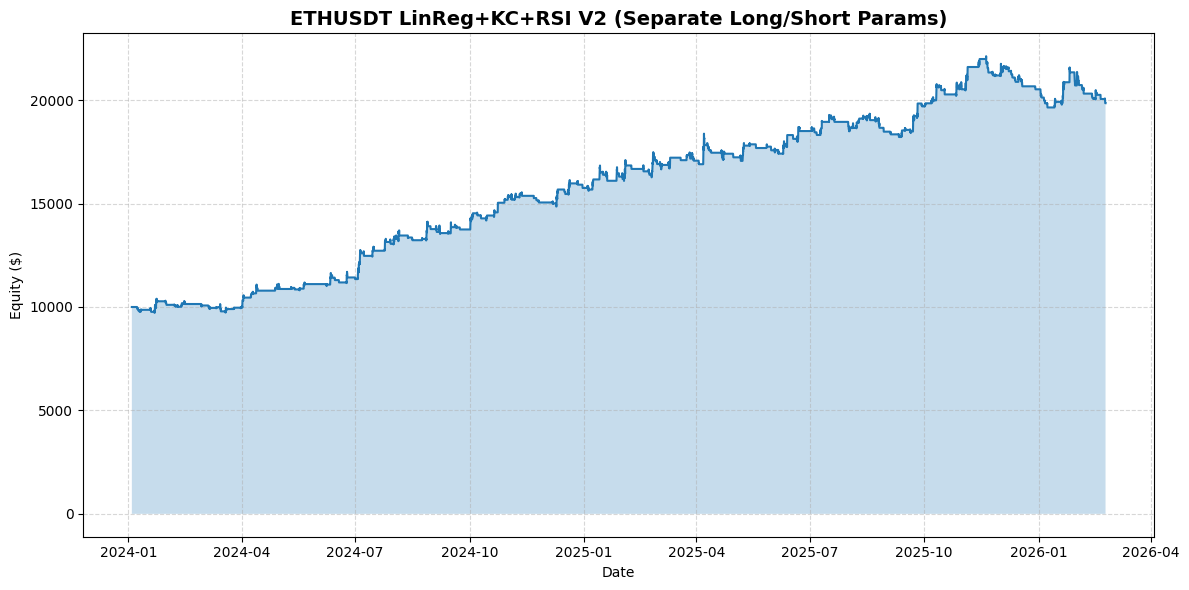


📊 Sample Trades (first 10):
            Exit Time   Type        Entry         Exit       Qty         PnL       Reason       Balance
0 2024-01-08 06:00:00  SHORT  2182.072874  2204.966935  4.367945 -100.000000    Stop Loss   9900.000000
1 2024-01-09 00:00:00   LONG  2335.980000  2303.798625  2.153419  -69.300000    Stop Loss   9830.700000
2 2024-01-10 02:00:00   LONG  2398.640000  2352.512357  1.491836  -68.814900    Stop Loss   9761.885100
3 2024-01-11 09:00:00   LONG  2521.815557  2608.680000  1.173397  101.926468    Time Exit   9863.811568
4 2024-01-19 10:00:00  SHORT  2463.600000  2489.934580  3.745574  -98.638116    Stop Loss   9765.173452
5 2024-01-22 10:00:00  SHORT  2429.447844  2377.178619  6.150269  321.469779  Take Profit  10086.643231
6 2024-01-22 13:00:00  SHORT  2380.827778  2403.305141  4.487467 -100.866432    Stop Loss   9985.776798
7 2024-01-23 09:00:00  SHORT  2337.246579  2257.102997  3.774989  302.541104  Take Profit  10288.317902
8 2024-01-24 05:00:00  SHORT  2223.

In [4]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =========================
# 1) FETCH BINANCE DATA
# =========================
def str_to_millis(date_str):
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol, interval, start_str, end_str):
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break

            data = response.json()
            if not data:
                break

            all_klines.extend(data)
            start_time = data[-1][0] + 1
            time.sleep(0.05)

        except Exception as e:
            print(f"Lỗi fetch: {e}")
            break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df


# =========================
# 2) INDICATORS
# =========================
def calculate_indicators(df):
    data = df.copy()

    # True Range
    data["prev_close"] = data["Close"].shift(1)
    data["h_l"] = data["High"] - data["Low"]
    data["h_pc"] = (data["High"] - data["prev_close"]).abs()
    data["l_pc"] = (data["Low"] - data["prev_close"]).abs()
    data["TR"] = data[["h_l", "h_pc", "l_pc"]].max(axis=1)

    # ATR (Wilder)
    def calc_atr(series_tr, period):
        return series_tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

    data["ATR_20"] = calc_atr(data["TR"], 20)
    data["ATR_25"] = calc_atr(data["TR"], 25)
    data["ATR_35"] = calc_atr(data["TR"], 35)
    data["ATR_50"] = calc_atr(data["TR"], 50)

    # Linear Regression (77) on Close
    def calc_linreg(series, period):
        out = pd.Series(index=series.index, dtype=float)
        x = np.arange(period)
        for i in range(period - 1, len(series)):
            y = series.iloc[i - period + 1:i + 1].values
            coef = np.polyfit(x, y, 1)  # slope, intercept
            out.iloc[i] = coef[0] * (period - 1) + coef[1]
        return out

    data["LinReg_77"] = calc_linreg(data["Close"], 77)

    # RSI(40) on Close
    def calc_rsi(series, period):
        delta = series.diff()
        gain = delta.where(delta > 0, 0.0).rolling(window=period).mean()
        loss = (-delta.where(delta < 0, 0.0)).rolling(window=period).mean()
        rs = gain / loss
        return 100 - (100 / (1 + rs))

    data["RSI_40"] = calc_rsi(data["Close"], 40)

    # Keltner Channel (35, 2.3)
    data["EMA_35"] = data["Close"].ewm(span=35, adjust=False).mean()
    data["KC_Upper_35"] = data["EMA_35"] + 2.3 * data["ATR_35"]
    data["KC_Lower_35"] = data["EMA_35"] - 2.3 * data["ATR_35"]

    # Highest/Lowest Close (10)
    data["Highest_Close_10"] = data["Close"].rolling(window=10).max()
    data["Lowest_Close_10"] = data["Close"].rolling(window=10).min()

    data.dropna(inplace=True)
    return data


# =========================
# 3) BACKTESTER V2 (Separate Long/Short Params)
# =========================
class LinRegKCRSIBacktesterV2:
    def __init__(self, df, initial_balance=10000):
        self.df = df
        self.initial_balance = float(initial_balance)
        self.balance = float(initial_balance)

        self.equity_curve = []
        self.trades = []

        self.position = None   # "LONG"/"SHORT"/None
        self.entry_price = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self.qty = 0.0
        self.entry_bar_idx = 0

        self.pending_order = None  # dict

        # ===== Risk (separate long/short) =====
        self.risk_pct_long = 0.008   # 0.8%
        self.risk_pct_short = 0.010  # 1.0%

        # ===== LONG params =====
        self.long_entry_mult = 2.6
        self.long_sl_coef = 1.6
        self.long_tp_coef = 4.0
        self.long_exit_after_bars = 12
        self.long_pending_expiration = 3

        # ===== SHORT params =====
        self.short_entry_mult = 2.2
        self.short_sl_coef = 1.5
        self.short_tp_coef = 4.8
        self.short_exit_after_bars = 18
        self.short_pending_expiration = 3

        # Optional stricter long filter (can tune)
        self.use_long_extra_filter = False
        self.use_short_extra_filter = False

    def run(self):
        idxs = self.df.index

        for i in range(len(self.df)):
            bar = self.df.iloc[i]
            t = idxs[i]

            # -----------------------------------
            # A) Manage open position
            # -----------------------------------
            if self.position is not None:
                held = i - self.entry_bar_idx

                # Side-specific time exit
                if self.position == "LONG":
                    max_hold = self.long_exit_after_bars
                else:
                    max_hold = self.short_exit_after_bars

                if held >= max_hold:
                    self.close_position(bar["Close"], t, "Time Exit")
                    self.append_equity(t)
                    continue

                # SL/TP intrabar check
                if self.position == "LONG":
                    if bar["Low"] <= self.sl:
                        self.close_position(self.sl, t, "Stop Loss")
                        self.append_equity(t)
                        continue
                    if bar["High"] >= self.tp:
                        self.close_position(self.tp, t, "Take Profit")
                        self.append_equity(t)
                        continue

                elif self.position == "SHORT":
                    if bar["High"] >= self.sl:
                        self.close_position(self.sl, t, "Stop Loss")
                        self.append_equity(t)
                        continue
                    if bar["Low"] <= self.tp:
                        self.close_position(self.tp, t, "Take Profit")
                        self.append_equity(t)
                        continue

            # -----------------------------------
            # B) Manage pending order
            # -----------------------------------
            if self.position is None and self.pending_order is not None:
                if i >= self.pending_order["expire_idx"]:
                    self.pending_order = None
                else:
                    p = self.pending_order["price"]

                    if self.pending_order["type"] == "BUY_STOP":
                        if bar["High"] >= p:
                            fill = max(p, bar["Open"])
                            self.open_position(
                                pos_type="LONG",
                                price=fill,
                                bar_idx=i,
                                sl_dist=self.pending_order["sl_dist"],
                                tp_dist=self.pending_order["tp_dist"]
                            )
                            self.pending_order = None

                    elif self.pending_order["type"] == "SELL_STOP":
                        if bar["Low"] <= p:
                            fill = min(p, bar["Open"])
                            self.open_position(
                                pos_type="SHORT",
                                price=fill,
                                bar_idx=i,
                                sl_dist=self.pending_order["sl_dist"],
                                tp_dist=self.pending_order["tp_dist"]
                            )
                            self.pending_order = None

            # -----------------------------------
            # C) Generate signals -> place pending
            # -----------------------------------
            if self.position is None and self.pending_order is None:
                # Need enough bars for RSI shift=4 and rolling indicators
                if i < 4:
                    self.append_equity(t)
                    continue

                open_0 = bar["Open"]

                # shift=1 trend filter
                linreg_1 = self.df.iloc[i-1]["LinReg_77"]

                # RSI momentum shift=4 vs shift=3
                rsi_4 = self.df.iloc[i-4]["RSI_40"]
                rsi_3 = self.df.iloc[i-3]["RSI_40"]

                # KC filter shift=1
                kc_up_1 = self.df.iloc[i-1]["KC_Upper_35"]
                kc_lo_1 = self.df.iloc[i-1]["KC_Lower_35"]

                # Optional extra filter examples
                long_extra_ok = True
                short_extra_ok = True

                if self.use_long_extra_filter:
                    # Example: require close_1 > EMA35_1
                    close_1 = self.df.iloc[i-1]["Close"]
                    ema35_1 = self.df.iloc[i-1]["EMA_35"]
                    long_extra_ok = close_1 > ema35_1

                if self.use_short_extra_filter:
                    close_1 = self.df.iloc[i-1]["Close"]
                    ema35_1 = self.df.iloc[i-1]["EMA_35"]
                    short_extra_ok = close_1 < ema35_1

                long_signal = (
                    (open_0 > linreg_1) and
                    (rsi_4 < rsi_3) and
                    (open_0 > kc_up_1) and
                    long_extra_ok
                )

                short_signal = (
                    (open_0 < linreg_1) and
                    (rsi_4 > rsi_3) and
                    (open_0 < kc_lo_1) and
                    short_extra_ok
                )

                if (not long_signal) and (not short_signal):
                    self.append_equity(t)
                    continue

                # Shared inputs for entries
                highest_close_3 = self.df.iloc[i-3]["Highest_Close_10"]
                lowest_close_3 = self.df.iloc[i-3]["Lowest_Close_10"]
                atr50_3 = self.df.iloc[i-3]["ATR_50"]

                atr20_1 = self.df.iloc[i-1]["ATR_20"]
                atr25_1 = self.df.iloc[i-1]["ATR_25"]

                # If both true (rare), ưu tiên phía mạnh hơn theo khoảng cách khỏi LinReg
                if long_signal and short_signal:
                    dist = open_0 - linreg_1
                    long_signal = dist >= 0
                    short_signal = not long_signal

                if long_signal:
                    entry = highest_close_3 + self.long_entry_mult * atr50_3
                    sl_dist = self.long_sl_coef * atr20_1
                    tp_dist = self.long_tp_coef * atr25_1

                    self.pending_order = {
                        "type": "BUY_STOP",
                        "price": float(entry),
                        "sl_dist": float(sl_dist),
                        "tp_dist": float(tp_dist),
                        "expire_idx": i + int(self.long_pending_expiration)
                    }

                elif short_signal:
                    entry = lowest_close_3 - self.short_entry_mult * atr50_3
                    sl_dist = self.short_sl_coef * atr20_1
                    tp_dist = self.short_tp_coef * atr25_1

                    self.pending_order = {
                        "type": "SELL_STOP",
                        "price": float(entry),
                        "sl_dist": float(sl_dist),
                        "tp_dist": float(tp_dist),
                        "expire_idx": i + int(self.short_pending_expiration)
                    }

            # -----------------------------------
            # D) Append MTM equity
            # -----------------------------------
            self.append_equity(t)

    def append_equity(self, t):
        mtm = self.balance
        close_px = self.df.loc[t, "Close"]

        if self.position == "LONG":
            mtm += (close_px - self.entry_price) * self.qty
        elif self.position == "SHORT":
            mtm += (self.entry_price - close_px) * self.qty

        self.equity_curve.append({"time": t, "equity": mtm})

    def open_position(self, pos_type, price, bar_idx, sl_dist, tp_dist):
        self.position = pos_type
        self.entry_price = float(price)
        self.entry_bar_idx = int(bar_idx)

        if pos_type == "LONG":
            self.sl = self.entry_price - sl_dist
            self.tp = self.entry_price + tp_dist
            risk_pct = self.risk_pct_long
        else:
            self.sl = self.entry_price + sl_dist
            self.tp = self.entry_price - tp_dist
            risk_pct = self.risk_pct_short

        risk_amount = self.balance * risk_pct
        sl_distance = abs(self.entry_price - self.sl)
        self.qty = float(risk_amount / sl_distance) if sl_distance > 0 else 0.0

    def close_position(self, price, t, reason):
        price = float(price)

        if self.position == "LONG":
            pnl = (price - self.entry_price) * self.qty
        else:
            pnl = (self.entry_price - price) * self.qty

        self.balance += pnl

        self.trades.append({
            "Exit Time": t,
            "Type": self.position,
            "Entry": self.entry_price,
            "Exit": price,
            "Qty": self.qty,
            "PnL": pnl,
            "Reason": reason,
            "Balance": self.balance
        })

        self.position = None
        self.entry_price = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self.qty = 0.0
        self.entry_bar_idx = 0


# =========================
# 4) METRICS
# =========================
def calculate_metrics(trades_df, equity_data, initial_balance):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index("time", inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep="last")]

    final_equity = eq_df["equity"].iloc[-1]
    total_return = (final_equity - initial_balance) / initial_balance

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25 if days > 0 else 0
    cagr = ((final_equity / initial_balance) ** (1 / years) - 1) if years > 0 else 0

    running_max = eq_df["equity"].cummax()
    drawdown = (eq_df["equity"] - running_max) / running_max
    max_dd = drawdown.min()

    eq_df["returns"] = eq_df["equity"].pct_change()
    mean_ret = eq_df["returns"].mean()
    std_ret = eq_df["returns"].std()
    bars_per_year = len(eq_df) / years if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret != 0 else 0

    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df["PnL"] > 0])
    win_rate = win_trades / total_trades if total_trades > 0 else 0
    avg_pnl = trades_df["PnL"].mean() if total_trades > 0 else 0

    gross_profit = trades_df[trades_df["PnL"] > 0]["PnL"].sum()
    gross_loss = abs(trades_df[trades_df["PnL"] < 0]["PnL"].sum())
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else 0

    return {
        "Final Equity": final_equity,
        "Total Return": total_return,
        "CAGR (approx)": cagr,
        "Max Drawdown": max_dd,
        "Sharpe": sharpe,
        "Trades": total_trades,
        "Winrate": win_rate,
        "Avg PnL/Trade": avg_pnl,
        "Profit Factor": profit_factor,
        "equity_df": eq_df
    }


def analyze_long_short(trades_df):
    if trades_df.empty:
        return pd.DataFrame()

    rows = []
    for side in ["LONG", "SHORT"]:
        d = trades_df[trades_df["Type"] == side].copy()
        if d.empty:
            rows.append({
                "Type": side,
                "Total_Trades": 0,
                "Wins": 0,
                "Losses": 0,
                "Win_Rate": 0.0,
                "Avg_PnL": 0.0,
                "Gross_Profit": 0.0,
                "Gross_Loss": 0.0,
                "Profit_Factor": 0.0
            })
            continue

        wins = d[d["PnL"] > 0]
        losses = d[d["PnL"] < 0]
        gross_profit = wins["PnL"].sum()
        gross_loss = abs(losses["PnL"].sum())
        pf = gross_profit / gross_loss if gross_loss > 0 else np.inf

        rows.append({
            "Type": side,
            "Total_Trades": len(d),
            "Wins": len(wins),
            "Losses": len(losses),
            "Win_Rate": len(wins) / len(d),
            "Avg_PnL": d["PnL"].mean(),
            "Gross_Profit": gross_profit,
            "Gross_Loss": gross_loss,
            "Profit_Factor": pf
        })

    out = pd.DataFrame(rows).set_index("Type")
    return out


def print_report_and_plot(metrics, symbol):
    print("\n" + "=" * 70)
    print("METRICS (LinReg + KC + RSI) V2 - Separate Long/Short Params")
    print("=" * 70)
    print(f"     Final Equity: {metrics['Final Equity']:.4f}")
    print(f"     Total Return: {metrics['Total Return']:.4f}")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']:.4f}")
    print(f"     Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']:.4f}")
    print(f"    Avg PnL/Trade: {metrics['Avg PnL/Trade']:.4f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.4f}")
    print("=" * 70)

    eq_df = metrics["equity_df"]
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df["equity"], linewidth=1.5)
    plt.fill_between(eq_df.index, eq_df["equity"], alpha=0.25)
    plt.title(f"{symbol} LinReg+KC+RSI V2 (Separate Long/Short Params)", fontsize=14, fontweight="bold")
    plt.xlabel("Date")
    plt.ylabel("Equity ($)")
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


# =========================
# 5) MAIN
# =========================
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "1h"
    start_date = "01/01/2024"
    end_date = "23/02/2026"

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) > 300:
        print("✅ Dữ liệu sẵn sàng. Tính indicators...")
        df_calc = calculate_indicators(df_raw)

        print("🚀 Đang chạy Backtest V2 (separate Long/Short params)...")
        bt = LinRegKCRSIBacktesterV2(df_calc, initial_balance=10000)

        # ===== QUICK TUNING (gợi ý từ stats bạn đưa) =====
        # Long yếu hơn -> lọc chặt hơn
        bt.risk_pct_long = 0.007
        bt.long_entry_mult = 2.6
        bt.long_sl_coef = 1.6
        bt.long_tp_coef = 4.0
        bt.long_exit_after_bars = 12
        bt.long_pending_expiration = 3

        # Short mạnh hơn -> cho "thở" hơn một chút
        bt.risk_pct_short = 0.010
        bt.short_entry_mult = 2.2
        bt.short_sl_coef = 1.5
        bt.short_tp_coef = 4.8
        bt.short_exit_after_bars = 18
        bt.short_pending_expiration = 3

        bt.run()

        trades_df = pd.DataFrame(bt.trades)

        if not trades_df.empty:
            metrics = calculate_metrics(trades_df, bt.equity_curve, bt.initial_balance)
            print_report_and_plot(metrics, symbol)

            print("\n📊 Sample Trades (first 10):")
            print(trades_df.head(10).to_string())

            print("\n📊 Exit Reasons Distribution:")
            print(trades_df["Reason"].value_counts())

            print("\n📊 Long vs Short Distribution:")
            print(trades_df["Type"].value_counts())

            print("\n📊 Winrate theo từng phía (Long/Short):")
            side_stats = analyze_long_short(trades_df)
            print(side_stats.to_string(float_format=lambda x: f"{x:.4f}"))
        else:
            print("⚠️ Không có lệnh nào được thực hiện.")
    else:
        print("❌ Không đủ dữ liệu.")

⏳ Đang tải dữ liệu ETHUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính indicators...
🚀 Đang chạy Backtest V2.1 (Separate Long/Short + Fee + Slippage)...

METRICS (LinReg + KC + RSI) V2.1 - Separate Long/Short + Fee + Slippage
     Final Equity: 14567.1906
     Total Return: 0.4567
    CAGR (approx): 0.1924
     Max Drawdown: -0.1427
           Sharpe: 1.1702
           Trades: 274
          Winrate: 0.4051
    Avg PnL/Trade: 16.6686
    Profit Factor: 1.2338


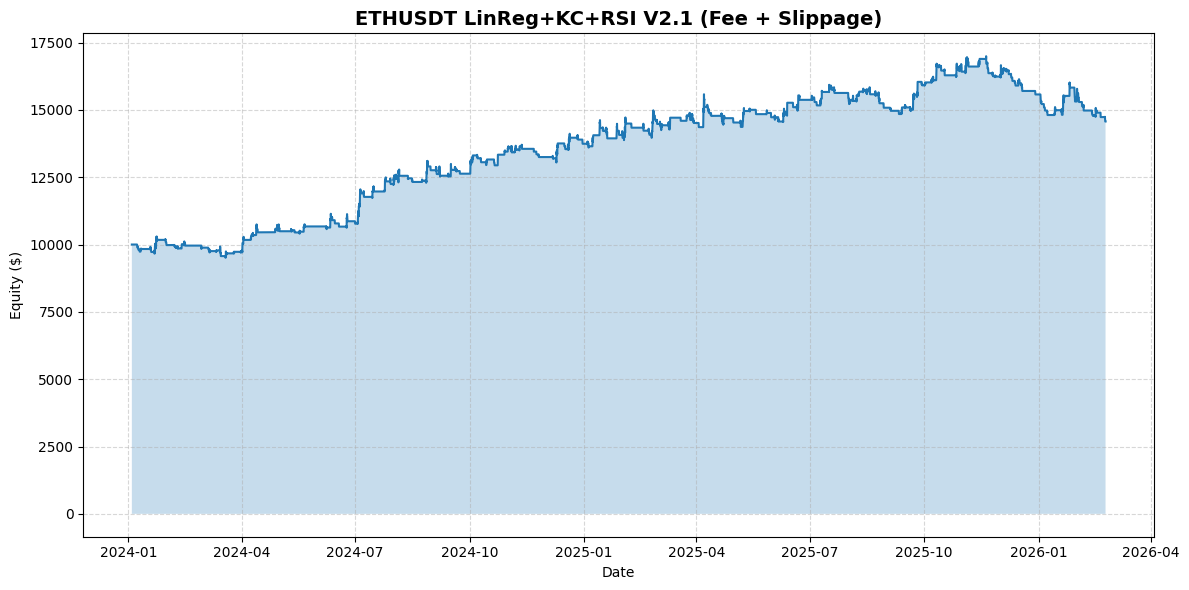


📊 Sample Trades (first 10):
            Exit Time   Type    Entry_Raw        Entry     Exit_Raw         Exit       Qty   PnL_gross  EntryCost  ExitCost  TotalCost     PnL_net       Reason       Balance
0 2024-01-08 06:00:00  SHORT  2182.072874  2181.636459  2204.530520  2204.971426  4.367945 -101.925854   5.717561  5.778716  11.496277 -113.422131    Stop Loss   9886.577869
1 2024-01-09 00:00:00   LONG  2335.980000  2336.447196  2304.265821  2303.804968  2.150500  -70.197110   3.014718  2.972599   5.987317  -76.184427    Stop Loss   9810.393442
2 2024-01-10 02:00:00   LONG  2398.640000  2399.119728  2352.992085  2352.521486  1.488755  -69.373360   2.143021  2.101397   4.244417  -73.617777    Stop Loss   9736.775665
3 2024-01-11 09:00:00   LONG  2521.815557  2522.319920  2608.680000  2608.158264  1.170379  100.463369   1.771242  1.831520   3.602761   96.860607    Time Exit   9833.636272
4 2024-01-19 10:00:00  SHORT  2463.600000  2463.107280  2489.441860  2489.939749  3.734115 -100.19553

In [5]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =========================
# 1) FETCH BINANCE DATA
# =========================
def str_to_millis(date_str):
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol, interval, start_str, end_str):
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break

            data = response.json()
            if not data:
                break

            all_klines.extend(data)
            start_time = data[-1][0] + 1
            time.sleep(0.05)

        except Exception as e:
            print(f"Lỗi fetch: {e}")
            break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df


# =========================
# 2) INDICATORS
# =========================
def calculate_indicators(df):
    data = df.copy()

    # True Range
    data["prev_close"] = data["Close"].shift(1)
    data["h_l"] = data["High"] - data["Low"]
    data["h_pc"] = (data["High"] - data["prev_close"]).abs()
    data["l_pc"] = (data["Low"] - data["prev_close"]).abs()
    data["TR"] = data[["h_l", "h_pc", "l_pc"]].max(axis=1)

    # ATR (Wilder)
    def calc_atr(series_tr, period):
        return series_tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

    data["ATR_20"] = calc_atr(data["TR"], 20)
    data["ATR_25"] = calc_atr(data["TR"], 25)
    data["ATR_35"] = calc_atr(data["TR"], 35)
    data["ATR_50"] = calc_atr(data["TR"], 50)

    # Linear Regression (77) on Close
    def calc_linreg(series, period):
        out = pd.Series(index=series.index, dtype=float)
        x = np.arange(period)
        for i in range(period - 1, len(series)):
            y = series.iloc[i - period + 1:i + 1].values
            coef = np.polyfit(x, y, 1)  # slope, intercept
            out.iloc[i] = coef[0] * (period - 1) + coef[1]
        return out

    data["LinReg_77"] = calc_linreg(data["Close"], 77)

    # RSI(40) on Close
    def calc_rsi(series, period):
        delta = series.diff()
        gain = delta.where(delta > 0, 0.0).rolling(window=period).mean()
        loss = (-delta.where(delta < 0, 0.0)).rolling(window=period).mean()
        rs = gain / loss
        return 100 - (100 / (1 + rs))

    data["RSI_40"] = calc_rsi(data["Close"], 40)

    # Keltner Channel (35, 2.3)
    data["EMA_35"] = data["Close"].ewm(span=35, adjust=False).mean()
    data["KC_Upper_35"] = data["EMA_35"] + 2.3 * data["ATR_35"]
    data["KC_Lower_35"] = data["EMA_35"] - 2.3 * data["ATR_35"]

    # Highest/Lowest Close (10)
    data["Highest_Close_10"] = data["Close"].rolling(window=10).max()
    data["Lowest_Close_10"] = data["Close"].rolling(window=10).min()

    data.dropna(inplace=True)
    return data


# =========================
# 3) BACKTESTER V2.1 (Separate Long/Short + Fee + Slippage)
# =========================
class LinRegKCRSIBacktesterV21:
    def __init__(self, df, initial_balance=10000):
        self.df = df
        self.initial_balance = float(initial_balance)
        self.balance = float(initial_balance)

        self.equity_curve = []
        self.trades = []

        self.position = None   # "LONG"/"SHORT"/None
        self.entry_price = 0.0            # filled price after slippage
        self.entry_price_raw = 0.0        # raw fill before slippage
        self.sl = 0.0
        self.tp = 0.0
        self.qty = 0.0
        self.entry_bar_idx = 0
        self.entry_cost = 0.0             # fee + slippage cost booked at entry

        self.pending_order = None

        # ===== Risk (separate long/short) =====
        self.risk_pct_long = 0.007
        self.risk_pct_short = 0.010

        # ===== LONG params =====
        self.long_entry_mult = 2.6
        self.long_sl_coef = 1.6
        self.long_tp_coef = 4.0
        self.long_exit_after_bars = 12
        self.long_pending_expiration = 3

        # ===== SHORT params =====
        self.short_entry_mult = 2.2
        self.short_sl_coef = 1.5
        self.short_tp_coef = 4.8
        self.short_exit_after_bars = 18
        self.short_pending_expiration = 3

        # ===== Trading costs =====
        # Futures taker thường ~ 0.04% = 0.0004 (tùy VIP)
        self.fee_rate = 0.0004

        # Slippage rate mỗi chiều (ví dụ 0.02% = 2 bps)
        # Tổng round-trip cost ~= fee*2 + slippage*2
        self.slippage_rate = 0.0002

        # Optional extra filters
        self.use_long_extra_filter = False
        self.use_short_extra_filter = False

    # ---------- Cost helpers ----------
    def _fee_cost(self, price, qty):
        return self.fee_rate * (price * qty)

    def _slippage_cost(self, price, qty):
        return self.slippage_rate * (price * qty)

    def _apply_entry_slippage(self, pos_type, raw_price):
        # Long buy -> giá xấu hơn (cao hơn)
        # Short sell -> giá xấu hơn (thấp hơn)
        if pos_type == "LONG":
            return raw_price * (1 + self.slippage_rate)
        else:
            return raw_price * (1 - self.slippage_rate)

    def _apply_exit_slippage(self, pos_type, raw_price):
        # Long exit (sell) -> giá xấu hơn (thấp hơn)
        # Short exit (buy cover) -> giá xấu hơn (cao hơn)
        if pos_type == "LONG":
            return raw_price * (1 - self.slippage_rate)
        else:
            return raw_price * (1 + self.slippage_rate)

    def run(self):
        idxs = self.df.index

        for i in range(len(self.df)):
            bar = self.df.iloc[i]
            t = idxs[i]

            # -----------------------------------
            # A) Manage open position
            # -----------------------------------
            if self.position is not None:
                held = i - self.entry_bar_idx
                max_hold = self.long_exit_after_bars if self.position == "LONG" else self.short_exit_after_bars

                if held >= max_hold:
                    self.close_position(raw_exit_price=bar["Close"], t=t, reason="Time Exit")
                    self.append_equity(t)
                    continue

                if self.position == "LONG":
                    if bar["Low"] <= self.sl:
                        self.close_position(raw_exit_price=self.sl, t=t, reason="Stop Loss")
                        self.append_equity(t)
                        continue
                    if bar["High"] >= self.tp:
                        self.close_position(raw_exit_price=self.tp, t=t, reason="Take Profit")
                        self.append_equity(t)
                        continue

                elif self.position == "SHORT":
                    if bar["High"] >= self.sl:
                        self.close_position(raw_exit_price=self.sl, t=t, reason="Stop Loss")
                        self.append_equity(t)
                        continue
                    if bar["Low"] <= self.tp:
                        self.close_position(raw_exit_price=self.tp, t=t, reason="Take Profit")
                        self.append_equity(t)
                        continue

            # -----------------------------------
            # B) Manage pending order
            # -----------------------------------
            if self.position is None and self.pending_order is not None:
                if i >= self.pending_order["expire_idx"]:
                    self.pending_order = None
                else:
                    p = self.pending_order["price"]

                    if self.pending_order["type"] == "BUY_STOP" and bar["High"] >= p:
                        raw_fill = max(p, bar["Open"])
                        self.open_position(
                            pos_type="LONG",
                            raw_price=raw_fill,
                            bar_idx=i,
                            sl_dist=self.pending_order["sl_dist"],
                            tp_dist=self.pending_order["tp_dist"]
                        )
                        self.pending_order = None

                    elif self.pending_order["type"] == "SELL_STOP" and bar["Low"] <= p:
                        raw_fill = min(p, bar["Open"])
                        self.open_position(
                            pos_type="SHORT",
                            raw_price=raw_fill,
                            bar_idx=i,
                            sl_dist=self.pending_order["sl_dist"],
                            tp_dist=self.pending_order["tp_dist"]
                        )
                        self.pending_order = None

            # -----------------------------------
            # C) Generate signals -> place pending
            # -----------------------------------
            if self.position is None and self.pending_order is None:
                if i < 4:
                    self.append_equity(t)
                    continue

                open_0 = bar["Open"]

                # Filters
                linreg_1 = self.df.iloc[i-1]["LinReg_77"]
                rsi_4 = self.df.iloc[i-4]["RSI_40"]
                rsi_3 = self.df.iloc[i-3]["RSI_40"]
                kc_up_1 = self.df.iloc[i-1]["KC_Upper_35"]
                kc_lo_1 = self.df.iloc[i-1]["KC_Lower_35"]

                long_extra_ok = True
                short_extra_ok = True

                if self.use_long_extra_filter:
                    close_1 = self.df.iloc[i-1]["Close"]
                    ema35_1 = self.df.iloc[i-1]["EMA_35"]
                    long_extra_ok = close_1 > ema35_1

                if self.use_short_extra_filter:
                    close_1 = self.df.iloc[i-1]["Close"]
                    ema35_1 = self.df.iloc[i-1]["EMA_35"]
                    short_extra_ok = close_1 < ema35_1

                long_signal = (
                    (open_0 > linreg_1) and
                    (rsi_4 < rsi_3) and
                    (open_0 > kc_up_1) and
                    long_extra_ok
                )

                short_signal = (
                    (open_0 < linreg_1) and
                    (rsi_4 > rsi_3) and
                    (open_0 < kc_lo_1) and
                    short_extra_ok
                )

                if (not long_signal) and (not short_signal):
                    self.append_equity(t)
                    continue

                # Entry params
                highest_close_3 = self.df.iloc[i-3]["Highest_Close_10"]
                lowest_close_3 = self.df.iloc[i-3]["Lowest_Close_10"]
                atr50_3 = self.df.iloc[i-3]["ATR_50"]

                # SL/TP params
                atr20_1 = self.df.iloc[i-1]["ATR_20"]
                atr25_1 = self.df.iloc[i-1]["ATR_25"]

                if long_signal and short_signal:
                    dist = open_0 - linreg_1
                    long_signal = dist >= 0
                    short_signal = not long_signal

                if long_signal:
                    entry = highest_close_3 + self.long_entry_mult * atr50_3
                    sl_dist = self.long_sl_coef * atr20_1
                    tp_dist = self.long_tp_coef * atr25_1

                    self.pending_order = {
                        "type": "BUY_STOP",
                        "price": float(entry),
                        "sl_dist": float(sl_dist),
                        "tp_dist": float(tp_dist),
                        "expire_idx": i + int(self.long_pending_expiration)
                    }

                elif short_signal:
                    entry = lowest_close_3 - self.short_entry_mult * atr50_3
                    sl_dist = self.short_sl_coef * atr20_1
                    tp_dist = self.short_tp_coef * atr25_1

                    self.pending_order = {
                        "type": "SELL_STOP",
                        "price": float(entry),
                        "sl_dist": float(sl_dist),
                        "tp_dist": float(tp_dist),
                        "expire_idx": i + int(self.short_pending_expiration)
                    }

            # -----------------------------------
            # D) Append MTM equity
            # -----------------------------------
            self.append_equity(t)

    def append_equity(self, t):
        mtm = self.balance
        close_px = self.df.loc[t, "Close"]

        if self.position == "LONG":
            # MTM unrealized chưa trừ exit cost (chuẩn hơn là conservative có thể trừ thêm 1 side cost)
            mtm += (close_px - self.entry_price) * self.qty
        elif self.position == "SHORT":
            mtm += (self.entry_price - close_px) * self.qty

        self.equity_curve.append({"time": t, "equity": mtm})

    def open_position(self, pos_type, raw_price, bar_idx, sl_dist, tp_dist):
        self.position = pos_type
        self.entry_bar_idx = int(bar_idx)

        # Apply entry slippage
        fill_price = self._apply_entry_slippage(pos_type, float(raw_price))
        self.entry_price_raw = float(raw_price)
        self.entry_price = float(fill_price)

        # SL/TP based on filled entry
        if pos_type == "LONG":
            self.sl = self.entry_price - sl_dist
            self.tp = self.entry_price + tp_dist
            risk_pct = self.risk_pct_long
        else:
            self.sl = self.entry_price + sl_dist
            self.tp = self.entry_price - tp_dist
            risk_pct = self.risk_pct_short

        # Risk-based sizing
        risk_amount = self.balance * risk_pct
        sl_distance = abs(self.entry_price - self.sl)
        self.qty = float(risk_amount / sl_distance) if sl_distance > 0 else 0.0

        # Entry costs (fee + slippage impact)
        entry_fee = self._fee_cost(self.entry_price, self.qty)
        entry_slip_cost = self._slippage_cost(self.entry_price, self.qty)
        self.entry_cost = entry_fee + entry_slip_cost

        # Trừ entry cost ngay khi vào lệnh
        self.balance -= self.entry_cost

    def close_position(self, raw_exit_price, t, reason):
        raw_exit_price = float(raw_exit_price)

        # Apply exit slippage
        exit_price = self._apply_exit_slippage(self.position, raw_exit_price)

        # Gross pnl from filled prices
        if self.position == "LONG":
            pnl_gross = (exit_price - self.entry_price) * self.qty
        else:
            pnl_gross = (self.entry_price - exit_price) * self.qty

        # Exit costs
        exit_fee = self._fee_cost(exit_price, self.qty)
        exit_slip_cost = self._slippage_cost(exit_price, self.qty)
        exit_cost = exit_fee + exit_slip_cost

        # Entry cost already deducted at open
        pnl_net_after_exit = pnl_gross - exit_cost
        self.balance += pnl_net_after_exit

        total_cost = self.entry_cost + exit_cost
        pnl_net_roundtrip = pnl_gross - total_cost

        self.trades.append({
            "Exit Time": t,
            "Type": self.position,
            "Entry_Raw": self.entry_price_raw,
            "Entry": self.entry_price,
            "Exit_Raw": raw_exit_price,
            "Exit": exit_price,
            "Qty": self.qty,
            "PnL_gross": pnl_gross,
            "EntryCost": self.entry_cost,
            "ExitCost": exit_cost,
            "TotalCost": total_cost,
            "PnL_net": pnl_net_roundtrip,
            "Reason": reason,
            "Balance": self.balance
        })

        # Reset
        self.position = None
        self.entry_price = 0.0
        self.entry_price_raw = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self.qty = 0.0
        self.entry_bar_idx = 0
        self.entry_cost = 0.0


# =========================
# 4) METRICS
# =========================
def calculate_metrics(trades_df, equity_data, initial_balance):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index("time", inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep="last")]

    final_equity = eq_df["equity"].iloc[-1]
    total_return = (final_equity - initial_balance) / initial_balance

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25 if days > 0 else 0
    cagr = ((final_equity / initial_balance) ** (1 / years) - 1) if years > 0 else 0

    running_max = eq_df["equity"].cummax()
    drawdown = (eq_df["equity"] - running_max) / running_max
    max_dd = drawdown.min()

    eq_df["returns"] = eq_df["equity"].pct_change()
    mean_ret = eq_df["returns"].mean()
    std_ret = eq_df["returns"].std()
    bars_per_year = len(eq_df) / years if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret != 0 else 0

    pnl_col = "PnL_net" if "PnL_net" in trades_df.columns else "PnL"

    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df[pnl_col] > 0])
    win_rate = win_trades / total_trades if total_trades > 0 else 0
    avg_pnl = trades_df[pnl_col].mean() if total_trades > 0 else 0

    gross_profit = trades_df[trades_df[pnl_col] > 0][pnl_col].sum()
    gross_loss = abs(trades_df[trades_df[pnl_col] < 0][pnl_col].sum())
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else 0

    return {
        "Final Equity": final_equity,
        "Total Return": total_return,
        "CAGR (approx)": cagr,
        "Max Drawdown": max_dd,
        "Sharpe": sharpe,
        "Trades": total_trades,
        "Winrate": win_rate,
        "Avg PnL/Trade": avg_pnl,
        "Profit Factor": profit_factor,
        "equity_df": eq_df
    }


def analyze_long_short(trades_df):
    if trades_df.empty:
        return pd.DataFrame()

    pnl_col = "PnL_net" if "PnL_net" in trades_df.columns else "PnL"
    rows = []

    for side in ["LONG", "SHORT"]:
        d = trades_df[trades_df["Type"] == side].copy()

        if d.empty:
            rows.append({
                "Type": side,
                "Total_Trades": 0,
                "Wins": 0,
                "Losses": 0,
                "Win_Rate": 0.0,
                "Avg_PnL": 0.0,
                "Gross_Profit": 0.0,
                "Gross_Loss": 0.0,
                "Profit_Factor": 0.0
            })
            continue

        wins = d[d[pnl_col] > 0]
        losses = d[d[pnl_col] < 0]

        gross_profit = wins[pnl_col].sum()
        gross_loss = abs(losses[pnl_col].sum())
        pf = gross_profit / gross_loss if gross_loss > 0 else np.inf

        rows.append({
            "Type": side,
            "Total_Trades": len(d),
            "Wins": len(wins),
            "Losses": len(losses),
            "Win_Rate": len(wins) / len(d),
            "Avg_PnL": d[pnl_col].mean(),
            "Gross_Profit": gross_profit,
            "Gross_Loss": gross_loss,
            "Profit_Factor": pf
        })

    return pd.DataFrame(rows).set_index("Type")


def print_report_and_plot(metrics, symbol):
    print("\n" + "=" * 75)
    print("METRICS (LinReg + KC + RSI) V2.1 - Separate Long/Short + Fee + Slippage")
    print("=" * 75)
    print(f"     Final Equity: {metrics['Final Equity']:.4f}")
    print(f"     Total Return: {metrics['Total Return']:.4f}")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']:.4f}")
    print(f"     Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']:.4f}")
    print(f"    Avg PnL/Trade: {metrics['Avg PnL/Trade']:.4f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.4f}")
    print("=" * 75)

    eq_df = metrics["equity_df"]
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df["equity"], linewidth=1.5)
    plt.fill_between(eq_df.index, eq_df["equity"], alpha=0.25)
    plt.title(f"{symbol} LinReg+KC+RSI V2.1 (Fee + Slippage)", fontsize=14, fontweight="bold")
    plt.xlabel("Date")
    plt.ylabel("Equity ($)")
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


# =========================
# 5) MAIN
# =========================
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "1h"
    start_date = "01/01/2024"
    end_date = "23/02/2026"

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) > 300:
        print("✅ Dữ liệu sẵn sàng. Tính indicators...")
        df_calc = calculate_indicators(df_raw)

        print("🚀 Đang chạy Backtest V2.1 (Separate Long/Short + Fee + Slippage)...")
        bt = LinRegKCRSIBacktesterV21(df_calc, initial_balance=10000)

        # ===== Tune riêng Long/Short (bạn chỉnh ở đây) =====
        # Long yếu hơn -> lọc/giảm risk
        bt.risk_pct_long = 0.007
        bt.long_entry_mult = 2.6
        bt.long_sl_coef = 1.6
        bt.long_tp_coef = 4.0
        bt.long_exit_after_bars = 12
        bt.long_pending_expiration = 3

        # Short mạnh hơn -> để chạy thoáng hơn
        bt.risk_pct_short = 0.010
        bt.short_entry_mult = 2.2
        bt.short_sl_coef = 1.5
        bt.short_tp_coef = 4.8
        bt.short_exit_after_bars = 18
        bt.short_pending_expiration = 3

        # ===== Cost settings =====
        bt.fee_rate = 0.0004        # 4 bps / side
        bt.slippage_rate = 0.0002   # 2 bps / side

        bt.run()

        trades_df = pd.DataFrame(bt.trades)

        if not trades_df.empty:
            metrics = calculate_metrics(trades_df, bt.equity_curve, bt.initial_balance)
            print_report_and_plot(metrics, symbol)

            print("\n📊 Sample Trades (first 10):")
            print(trades_df.head(10).to_string())

            print("\n📊 Exit Reasons Distribution:")
            print(trades_df["Reason"].value_counts())

            print("\n📊 Long vs Short Distribution:")
            print(trades_df["Type"].value_counts())

            print("\n📊 Winrate theo từng phía (Long/Short) [PnL_net]:")
            side_stats = analyze_long_short(trades_df)
            print(side_stats.to_string(float_format=lambda x: f"{x:.4f}"))

            print("\n📊 Tổng chi phí:")
            print(f"Total Entry Cost: {trades_df['EntryCost'].sum():.4f}")
            print(f"Total Exit Cost : {trades_df['ExitCost'].sum():.4f}")
            print(f"Total Cost      : {trades_df['TotalCost'].sum():.4f}")
        else:
            print("⚠️ Không có lệnh nào được thực hiện.")
    else:
        print("❌ Không đủ dữ liệu.")